# Week 8 · Text Processing

**CM3801 · CMT309/509 · CMT124** · shared session · Thursday 26 November 2026

**The question of the week:** how do we turn **messy text** into **structured information** that we can analyse?

By the end of today you can write regular expressions to search, extract and clean text; tokenise and normalise text with NLTK; explain the difference between stemming and lemmatisation; use part-of-speech tags and word counts to describe a text; say what each of your preprocessing choices changed; and compare two kinds of text source.

Today has three parts: **Hour 1** regular expressions · **Hour 2** NLTK text preprocessing · **Lab** the whole workflow on 34 real press releases.

<img alt="Raw text, regex find, clean and extract (Hour 1), tokenise, normalise, lemmas and POS tags (Hour 2), count and interpret; the lab does all of it" src="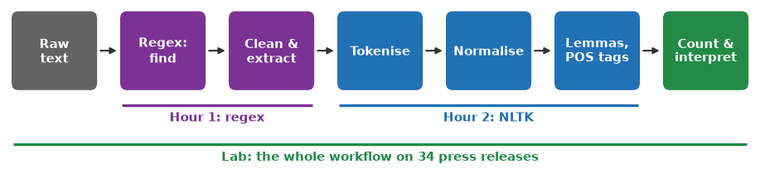">

### Setup

Run this cell first. It loads the course data helper and the libraries, and downloads the four small **NLTK data** packages we need in Hour 2 (once per runtime).

In [ ]:
# --- Setup: run this cell first -------------------------------------------------
# Course datasets live in the course repository under 2026-27/datasets/.
# get_data() uses a local copy if the notebook runs inside a copy of the repository;
# otherwise (e.g. in Google Colab) it downloads the file once and reuses it.
import os
import urllib.request

COURSE_REPO = "OWNER/REPO"
BASE_URL = f"https://raw.githubusercontent.com/{COURSE_REPO}/main/2026-27/"


def course_file(relpath):
    """Return a local path to a course file such as 'datasets/owid_co2_cleaned.csv'."""
    for root in ("../../..", "."):                     # 1) running inside a copy of the repository
        path = os.path.join(root, relpath)
        if os.path.exists(path):
            return path
    path = os.path.join("course_files", relpath)       # 2) Colab: download once
    if not os.path.exists(path):
        os.makedirs(os.path.dirname(path), exist_ok=True)
        urllib.request.urlretrieve(BASE_URL + relpath, path)
    return path


def get_data(name):
    """Return a local path to a course dataset, e.g. get_data('owid_co2_cleaned.csv')."""
    return course_file("datasets/" + name)


import re
import pandas as pd
import matplotlib.pyplot as plt
import nltk

NLTK_DATA = ["punkt_tab", "stopwords", "wordnet", "averaged_perceptron_tagger_eng"]
missing = [name for name in NLTK_DATA if not nltk.download(name, quiet=True)]
print("NLTK data ready" if not missing else f"Download failed, run this cell again: {missing}")

## Hour 1 · Regular expressions: finding patterns in text

### From strings to tables to text

In **Week 1** you searched and sliced strings with `in`, `.find()` and `.count()`. In **Weeks 6 and 7** you worked with tidy **tables** and drew **charts** from them. Most real data does not start as a tidy table: it starts as **text**, such as logs, reports, web pages and press releases. Today joins the two ends: messy text in, a table you can count and plot out.

### One messy text for the whole hour

A volunteer group keeps a shared river log. Everyone types differently: three date formats, `2.31m` and `2.87 m`, upper and lower case, double spaces, an e-mail address here and a link there. *(The log, the group and the addresses are made up.)*

In [ ]:
log = """TAFF VALLEY RIVER WATCH  -  volunteer log
03/02/2026 07:45  Station TVR-014 (Pontypridd):  level 2.31m , rain 18mm overnight.
   Reported by: dewi.jones@rivwatch.example   tel. 029 2018 0123
04/02/2026 08:10  Station TVR-014 (Pontypridd): level 2.87 m, rain 34 mm.  FLOOD ALERT issued!!
2026-02-04 19:30  station tvr-022 (Llandaff): level 1.9m; rain: 41mm ; see https://rivwatch.example/alerts/2026/feb
5 Feb 2026, 06:55  Station TVR-022 (Llandaff) - level 2.05 m - rain 12 mm - path closed near the weir
#flood #Cardiff  Volunteers needed this weekend -> email volunteers@rivwatch.example
06/02/2026 09:00  Station TVR-031 (Cardiff Bay): level 0.95m (falling), rain 0 mm.  No rain since Tuesday.
Donations so far: £1,250.50 (target £2,000)"""
print(log)

**Predict:** the log has five rain readings. What will `log.count("rain")` return?

In [ ]:
print("flood" in log)      # True, but which flood? where? how many?
print(log.find("2026"))    # the first position only
print(log.count("rain"))

`count` gives **6**: the readings (`rain 18mm`) and a remark (`No rain since Tuesday`) look the same to it. String methods answer *"is this exact text there?"*. They can't answer *"give me every date"* or *"every water level"*, because those are **shapes** of text, not fixed strings.

A **regular expression** (regex) describes a shape: "two digits, a slash, two digits, a slash, four digits". Python's `re` module searches text for that shape.

### Literal matching with `re.search`

The simplest pattern is plain text. `re.search(pattern, text)` returns the **first** match as a *match object*, or `None` if there is no match.

**Predict:** the log contains `flood` and `FLOOD`. Does `re.search("Flood", log)` find either of them?

In [ ]:
# ✍️ Type along: re.search, match objects and None

<details><summary>Code from class</summary>

```python
m = re.search("flood", log)
print(m)
print(m.group(), m.start(), m.end())          # the matched text and where it is

print(re.search("Flood", log))                         # case matters: None
print(re.search("Flood", log, flags=re.IGNORECASE))    # now 'FLOOD' (the 04/02 line) is found
```

</details>

Regex is case-sensitive, so `"Flood"` matches nothing and returns `None`. **Always test for `None`** before using a match (`if m: ...`): calling `.group()` on `None` is the most common regex error.

### Special characters and raw strings

Some characters are *instructions*, not text: `. ^ $ * + ? { } [ ] \ | ( )`. The dot means "any character". To mean a real dot, **escape** it: `\.`

Write patterns as **raw strings** `r"..."`, so that Python leaves the backslashes alone for `re`.

**Predict:** which of `2.31` and `2x31` does each pattern match?

In [ ]:
print(re.findall(r"2.31", "level 2.31m, not 2x31"))     # the dot matches any character
print(re.findall(r"2\.31", "level 2.31m, not 2x31"))    # escaped: a real dot only

`re.findall` returns **every** match as a list. The unescaped dot also matches the `x`.

### Character classes

A class matches **one** character from a set.

| Pattern | Matches one… |
|---|---|
| `[0-9]` or `\d` | digit |
| `[A-Za-z]` | letter |
| `\w` | "word" character: letter, digit or `_` |
| `\s` | whitespace: space, tab, newline |
| `[^0-9]` | anything *except* a digit |
| `.` | any character except a newline |

**Quick check:** the log has five readings. How many station codes will `TVR-\d\d\d` find, and why?

In [ ]:
print(re.findall(r"TVR-\d\d\d", log))
print(re.findall(r"[Tt][Vv][Rr]-\d\d\d", log))           # fix 1: a class for each letter
print(re.findall(r"TVR-\d\d\d", log, flags=re.IGNORECASE))  # fix 2: a flag

The first pattern finds four: `tvr-022` was typed in lower case. A class per letter or the `IGNORECASE` flag both fix it; the flag is easier to read.

### Quantifiers: how many?

| Quantifier | Meaning |
|---|---|
| `+` | one or more |
| `*` | zero or more |
| `?` | zero or one (optional) |
| `{3}` / `{2,4}` | exactly 3 / between 2 and 4 |

**Predict:** what does `re.findall(r"\d+", "rain 12mm, 3.5mm")` return?

In [ ]:
# ✍️ Type along: quantifiers

<details><summary>Code from class</summary>

```python
print(re.findall(r"\d+", "rain 12mm, 3.5mm"))         # runs of digits
print(re.findall(r"\d+\.?\d*", "rain 12mm, 3.5mm"))    # digits, an optional dot, more digits
print(re.findall(r"TVR-\d{3}", log, flags=re.I))      # the station pattern, shorter
print(re.findall(r"\d+\.\d+", log))                    # decimals: look at the last one!
```

</details>

`\d+` gives `['12', '3', '5']`: the dot is not a digit, so it breaks `3.5` into two runs. `\d+\.?\d*` keeps `3.5` together. And `\d+\.\d+` finds every decimal in the log, including `250.50` from the donations line: a pattern finds a **shape**, not a meaning.

**Your turn:** extract every **rainfall reading** from `log`: `18mm`, `34 mm`, `41mm`, … The space before `mm` is sometimes there and sometimes not.

In [ ]:
# your code here

<details><summary>Answer</summary>

```python
print(re.findall(r"\d+\s?mm", log))   # \s? = an optional space
```

Five readings: `18mm`, `34 mm`, `41mm`, `12 mm` and `0 mm`. `No rain` is not matched: there is no number in front of it.

</details>

### Anchors and word boundaries

Anchors match a **position**, not a character.

| Anchor | Position |
|---|---|
| `^` / `$` | start / end of the text (of each **line** with `re.MULTILINE`) |
| `\b` | a word boundary: between a word character and a non-word character |

In [ ]:
# Which lines start with a dd/mm/yyyy date?
print(re.findall(r"^\d{2}/\d{2}/\d{4}", log, flags=re.MULTILINE))

**Before we run this:** we want the water levels in metres. But `m` is also the first letter of `mm`. What will the first pattern catch by mistake?

In [ ]:
print(re.findall(r"\d+\.?\d*\s?m", log))       # catches '18m' out of '18mm'
print(re.findall(r"\d+\.?\d*\s?m\b", log))    # \b: the 'm' must END a word

`\b` removes `18m`, `34 m`, `41m`, `12 m` and `0 m`, all cut out of `mm`, and leaves the five levels.

**Discuss:** can you think of a line a volunteer might type that would *still* fool the second pattern? (Try `path closed for 200 m`.) A pattern is only as good as the text you tested it on.

### Groups: capture the parts you want

Brackets `( )` group part of a pattern **and capture it**. `|` means **or**, and `(?:...)` groups without capturing.

**Predict:** the date pattern below has three groups. What will each item of the `findall` result look like?

In [ ]:
# ✍️ Type along: groups

<details><summary>Code from class</summary>

```python
print(re.findall(r"(\d{2})/(\d{2})/(\d{4})", log))     # (day, month, year)
print(re.findall(r"(\d+\.\d+)\s?(m)\b", log))           # (number, unit)
print(re.findall(r"rain:?\s?(\d+)\s?mm", log))          # one group: just the numbers
```

</details>

With groups, `findall` returns only the captured parts: a **tuple** per match when there are several groups (`('03', '02', '2026')`), a plain string when there is one.

**Named groups** `(?P<name>...)` make longer patterns readable: you ask for a part by name instead of by number.

**Before we run this:** `.*?` is a lazy "anything": as few characters as possible (more in *Greedy and lazy*, after class). Which station and level will the **first** match pick up?

In [ ]:
m = re.search(r"(?P<station>TVR-\d{3}).*?level:?\s*(?P<level>\d+\.\d+)\s?m\b", log, flags=re.I)
print(m.group("station"), m.group("level"))
print(m.groupdict())

**Try it:** find every **e-mail address** in the log. Start simple (`\S+@\S+`), look at the result, then make the pattern stricter.

In [ ]:
# your code here

<details><summary>Answer</summary>

```python
print(re.findall(r"\S+@\S+", log))                       # works here, but would also grab trailing punctuation
print(re.findall(r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+", log))  # name @ domain . part(s)
```

`\S` is "any non-whitespace", so `\S+@\S+` would also take a full stop or a bracket at the end of a sentence. The second pattern only allows characters that can appear in an address.

</details>

### Three functions you will use all the time

| Function | Returns | Use it to… |
|---|---|---|
| `re.search(p, s)` | the first match object, or `None` | test for a pattern, get one match |
| `re.findall(p, s)` | a list of strings (tuples, with groups) | extract every match |
| `re.sub(p, repl, s)` | a new string | clean and replace |
| `re.finditer(p, s)` | an iterator of match objects | positions, named groups, building tables |
| `re.split(p, s)` | a list of pieces | split on a pattern, not a fixed separator |

Flags: `re.IGNORECASE` (`re.I`) · `re.MULTILINE` (`re.M`). `re.compile(p)` keeps a pattern you use many times.

### Cleaning with `re.sub`

`re.sub` replaces every match. The replacement can reuse captured groups: `\1`, `\2`, … (or `\g<name>`).

**Predict:** what does `re.sub(r"(\d{2})/(\d{2})/(\d{4})", r"\3-\2-\1", "03/02/2026")` give?

In [ ]:
# ✍️ Type along: clean the log one step at a time

<details><summary>Code from class</summary>

```python
clean = re.sub(r"(\d{2})/(\d{2})/(\d{4})", r"\3-\2-\1", log)       # dd/mm/yyyy -> yyyy-mm-dd
clean = re.sub(r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+", "<EMAIL>", clean)   # hide e-mail addresses
clean = re.sub(r"https?://\S+", "<URL>", clean)                      # replace links
clean = re.sub(r"!+", "!", clean)                                     # '!!' -> '!'
clean = re.sub(r"[ \t]+", " ", clean)                                 # runs of spaces -> one space
print(clean)
```

</details>

`2026-02-03`: group 3 (the year) first, then the month, then the day. That is the ISO date format, which sorts correctly as text. Clean in **small steps** and print after each one.

**Try it** *(optional)*: one reading uses a third date format, `5 Feb 2026`. Write a `re.sub` that turns the line below into `2026-02-05 ...`. One month is enough here.

In [ ]:
line = "5 Feb 2026, 06:55  Station TVR-022 (Llandaff) - level 2.05 m"
# your code here

<details><summary>Answer</summary>

```python
print(re.sub(r"\b(\d{1,2}) Feb (\d{4})", lambda m: f"{m.group(2)}-02-{int(m.group(1)):02d}", line))
```

The replacement can be a **function** (here a `lambda`, Week 4): it receives the match and returns the new text, so it can pad `5` to `05`. A dictionary of month names would handle all twelve months.

</details>

### From text to a table

Everything together: one pattern with named groups, `re.finditer`, and pandas. This is the step that turns *text* into *data*.

**Before we run this:** the log has five station readings. How many rows should the table have, and which columns?

In [ ]:
reading = re.compile(
    r"(?P<station>TVR-\d{3})"                          # station code
    r".*?level:?\s*(?P<level_m>\d+(?:\.\d+)?)\s?m\b"    # water level in metres
    r".*?rain:?\s*(?P<rain_mm>\d+)\s?mm",               # rainfall in mm
    flags=re.IGNORECASE,
)
rows = [m.groupdict() for m in reading.finditer(log)]
readings = pd.DataFrame(rows).astype({"level_m": float, "rain_mm": int})
readings["station"] = readings["station"].str.upper()
readings

Five readings, five rows, three typed columns: text has become a table you could sort, group or plot (Weeks 6 and 7).

**Discuss:** a volunteer types `rain 3.5 mm` instead of `rain 12 mm`. What happens to that row? Predict, then run the cell.

In [ ]:
log2 = log.replace("rain 12 mm", "rain 3.5 mm")
rows2 = [m.groupdict() for m in reading.finditer(log2)]
print(len(rows), "rows before,", len(rows2), "rows after, and no error")

The `rain_mm` group is `\d+`, so `3.5` no longer fits and the whole reading **disappears silently**. Always compare the number of matches with what you expect, for example with the number of lines that contain `TVR-`.

### Regex: good habits

| Build patterns in small steps | Watch out |
|---|---|
| 1. start with a literal piece of a real example | a row that does not match **disappears silently**: count matches against what you expect |
| 2. generalise one part at a time | regex is the wrong tool for nested structure (HTML, JSON): use a parser |
| 3. test on the **real** text and read the result | patterns are hard to read later: use raw strings, named groups and comments |
| 4. look at what is **missing**, not only at what was found | try patterns interactively at [regex101.com](https://regex101.com) (choose the *Python* flavour) |

### Takeaways: regular expressions

* A regex describes the **shape** of text: classes (`\d`, `\w`, `\s`), quantifiers (`+`, `*`, `?`, `{n}`), anchors (`^`, `$`, `\b`).
* `re.search` to test, `re.findall` to extract, `re.sub` to clean; **groups** capture only the parts you need.
* Use raw strings `r"..."`, and escape special characters (`\.`).
* Named groups + `finditer` + pandas turn text into a table.
* Test on the real text, and check what your pattern **misses**.

### Two kinds of text source

The river log and the press releases of Hour 2 were collected in very different ways, and that changes what you can trust them for.

**Discuss:** you want to know how often rivers flooded in South Wales in 2026. What would a **volunteer log** like ours be good for, and what would the Environment Agency's **published press releases** on GOV.UK be good for?

<details><summary>Answer</summary>

| | **Volunteer (citizen) log** | **Published GOV.UK press releases** |
|---|---|---|
| Coverage | only the stations and days volunteers visit; local and detailed | what the agency chose to announce: national, but **selective** |
| Reliability | mixed formats, typos, unchecked readings (`tvr-022`) | edited and consistent, but written to inform, not to record every event |
| Documentation | often none: who measured, how, with what? | publisher and date on every release |
| Licence | unclear unless the group states one: ask first | Open Government Licence v3.0: free to reuse **with attribution** |
| Personal data | names, e-mails, phone numbers: collect only what you need; remove them before sharing | statements by an organisation; little personal data |

Neither counts all floods: the log has gaps in space and time, and press releases report what was **newsworthy**. Use measured river levels for the count, and both texts as supporting evidence.

</details>

Before you reuse any text, check **who published it and why**, **under which licence**, and whether it contains **personal data**.

## Hour 2 · NLTK: from text to words

### What is preprocessing for?

Regex found **patterns** we could describe. Now we want **words**: which words a text uses, how often, and in what role. A computer can't count words until we decide what a "word" **is**, and every decision keeps some information and throws some away.

**NLTK** (the Natural Language Toolkit) is a long-standing Python library for **classical, transparent** text processing: every step is a small function whose output you can read. It is not "modern NLP" (language models, embeddings), but those still start from cleaned, inspected text.

<img alt="The preprocessing pipeline: clean with regex, tokenise, POS-tag, lower-case and keep words, drop stop words, lemmatise with POS, count" src="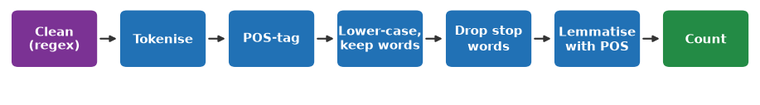">

NLTK separates its **code** (the `nltk` package, already in Colab) from its **data**. The setup cell downloaded the four data packages this session uses:

| Data package | Used by |
|---|---|
| `punkt_tab` | `word_tokenize`, `sent_tokenize` |
| `stopwords` | `stopwords.words("english")` |
| `wordnet` | `WordNetLemmatizer` |
| `averaged_perceptron_tagger_eng` | `pos_tag` |

Older tutorials download `punkt` and `averaged_perceptron_tagger`: those names no longer work with current NLTK. If a call fails with `LookupError: Resource ... not found`, the message names the missing package; download **that** name.

### Our text: one real press release

The lab corpus has 34 Environment Agency press releases about floods and drought from 2026. This hour uses one of them, *Drought declared in half of England*.

In [ ]:
press = pd.read_csv(get_data("ea_flood_drought_press_2026.csv"))
doc = press.loc[press["doc_id"] == "EA-026"].iloc[0]
print(doc["title"], "|", doc["published"][:10], "|", len(doc["text"]), "characters")
print(doc["text"][:300])

### Tokenisation

A **token** is one unit of text, usually a word or a punctuation mark.

**Predict:** how will `split()`, the regex `\w+` and NLTK's `word_tokenize` treat `We’re`, `long-term` and `industry,` in this sentence?

In [ ]:
# ✍️ Type along: three tokenisers on one sentence
sentence = "We’re delivering long-term change in the water industry, including nine new reservoirs."

<details><summary>Code from class</summary>

```python
sentence = "We’re delivering long-term change in the water industry, including nine new reservoirs."
print(sentence.split())                 # spaces only: punctuation sticks to words
print(re.findall(r"\w+", sentence))     # word characters only: "We’re" and "long-term" break apart
print(nltk.word_tokenize(sentence))     # NLTK: rules for English (punctuation, hyphens, clitics)
```

</details>

`split()` keeps `industry,` with its comma; `\w+` breaks `long-term` in two; `word_tokenize` handles both. But look at `We’re`: NLTK gives `We`, `’`, `re`.

NLTK's rules expect the **straight** apostrophe `'`, but published text uses the **curly** one `’`. One regex substitution fixes it: this is why regex comes first.

**Before we run this:** after straightening the apostrophe, how many tokens will `We're` become?

In [ ]:
sentence = "We’re delivering long-term change in the water industry, including nine new reservoirs."
straight = re.sub(r"[‘’]", "'", sentence)    # curly quotes -> straight
print(nltk.word_tokenize(straight))

Two: `We` and `'re`, as intended. From now on we **normalise the apostrophes first**, then tokenise. `sent_tokenize` splits a text into sentences in the same way:

In [ ]:
text = re.sub(r"[‘’]", "'", doc["text"])     # the whole press release, apostrophes straightened
sentences = nltk.sent_tokenize(text)
print(len(sentences), "sentences; the first:", sentences[0])

**Your turn:** tokenise the whole press release `text` with `nltk.word_tokenize`. How many tokens are there, and how many **distinct** tokens? Print the first 20: which tokens are not words?

In [ ]:
# your code here

<details><summary>Answer</summary>

```python
tokens = nltk.word_tokenize(text)
print(len(tokens), "tokens,", len(set(tokens)), "distinct")
print(tokens[:20])
```

`set()` (Week 2, optional) keeps one copy of each token. Punctuation marks (`.`, `,`, `-`) are tokens too.

</details>

### Normalisation: case and non-words

`Drought`, `drought` and `DROUGHT` are three different strings to Python. **Lower-casing** merges them; keeping only **alphabetic** tokens (`isalpha()`, Week 1) drops punctuation and numbers.

In [ ]:
tokens = nltk.word_tokenize(text)
lower = [t.lower() for t in tokens]
words = [t for t in lower if t.isalpha()]
print(len(set(tokens)), "distinct tokens ->", len(set(lower)), "after lower() ->",
      len(set(words)), "alphabetic")

Every normalisation step **throws information away**: lower-casing merges `US` (the country) and `us`; dropping non-alphabetic tokens loses `7%` and `2026`. That is fine if you say so: preprocessing is a set of **decisions**, not a fixed recipe.

### Stop words

**Stop words** are very frequent function words (`the`, `and`, `of`, …) that carry little topic. NLTK has a list for each language.

In [ ]:
from nltk.corpus import stopwords
stop = set(stopwords.words("english"))
content = [w for w in words if w not in stop]
print(len(stop), "stop words, e.g.", sorted(stop)[:8])
print(len(words), "words ->", len(content), "after removing stop words")

**Discuss:** `not` is on NLTK's stop-word list. Should it be a stop word when you analyse **flood warnings**? Think of a sentence where removing it reverses the meaning, then run the cell.

In [ ]:
warning = "Do not walk or drive through flood water."
print([w for w in nltk.word_tokenize(warning.lower()) if w.isalpha() and w not in stop])

The safety advice has become `walk drive flood water`. A stop-word list is a **default**, not a rule: for counting topics, dropping `not` is harmless; for anything about meaning (instructions, opinions), it can reverse it.

### Stemming vs lemmatisation

Both reduce words to a base form, so that `rivers` and `river` are counted together.

* A **stemmer** chops endings with rules (Porter). Fast, but the result need not be a word: `studies → studi`.
* A **lemmatiser** looks the word up in a dictionary (WordNet) and returns a real word, the **lemma**: `studies → study`. It needs to know the **part of speech** (noun, verb, adjective, …).

**Quick check:** what do the Porter stemmer and the WordNet lemmatiser (with no part of speech given) return for `"was"`?
1. `was` and `be`
2. `wa` and `be`
3. `wa` and `wa`

In [ ]:
from nltk.stem import PorterStemmer, WordNetLemmatizer
stemmer, lemmatiser = PorterStemmer(), WordNetLemmatizer()
print(stemmer.stem("was"), lemmatiser.lemmatize("was"), lemmatiser.lemmatize("was", pos="v"))

Answer 3: `wa` and `wa`. The stemmer chops the `s`. The lemmatiser **assumes a noun** unless told otherwise, and as a noun `was` looks like a plural, so it also strips the `s`. Told that it is a verb (`pos="v"`), it returns `be`. **A lemmatiser is only as good as the part of speech you give it.**

In [ ]:
for w in ["rivers", "studies", "flooding", "communities", "running", "better"]:
    print(f"{w:12} stem: {stemmer.stem(w):8} noun: {lemmatiser.lemmatize(w):10}",
          f"verb: {lemmatiser.lemmatize(w, 'v'):12} adj: {lemmatiser.lemmatize(w, 'a')}")

Read it row by row: `flooding` and `running` only become `flood` and `run` as verbs; `better` becomes `good` only as an adjective.

**Your turn:** stem and lemmatise (as a verb) the words `declared`, `using`, `replenish`, `held`, `rescues`. Which method would you use for a word-count chart that people will read, and why?

In [ ]:
# your code here

<details><summary>Answer</summary>

```python
for w in ["declared", "using", "replenish", "held", "rescues"]:
    print(f"{w:10} stem: {stemmer.stem(w):10} lemma (verb): {lemmatiser.lemmatize(w, pos='v')}")
```

The stems (`declar`, `use`, `replenish`, `held`, `rescu`) are not always words, and `held` stays `held`; the lemmas (`declare`, `use`, `replenish`, `hold`, `rescue`) are real words. For a chart that people read, use **lemmas**. Stems are fine inside a pipeline nobody reads.

</details>

### Part-of-speech (POS) tagging *(introductory)*

A POS tagger labels each token with its grammatical role. NLTK uses the Penn Treebank tags; you only need the first letters:

| Tag starts with | Meaning | Example |
|---|---|---|
| `NN` | noun (`NNS` plural, `NNP` proper noun) | drought, rivers, Thames |
| `VB` | verb (`VBD` past, `VBG` -ing, `VBN` participle) | declared, using |
| `JJ` | adjective | dry, exceptional |
| `RB` | adverb | very, currently |
| `CD` | number | 7, 2026 |

**Predict:** which tags will `England`, `declared` and `drought` get?

In [ ]:
headline = "Half of England has been declared in drought by the Environment Agency."
print(nltk.pos_tag(nltk.word_tokenize(headline)))

`England` is `NNP` (a proper noun), `declared` is `VBN` (a participle) and `drought` is `NN`. The tagger is a statistical model: usually right, sometimes wrong, especially on headlines and lists.

Tags help in two ways: they tell the lemmatiser the **part of speech**, and they let you keep one word type, such as the **nouns** (what a text is about). We tag the **original** tokens, because capital letters and context help the tagger.

**Before we run this:** which nouns do you expect at the top of a drought press release?

In [ ]:
def wordnet_pos(tag):
    """Map a Penn Treebank tag to the part of speech the lemmatiser understands."""
    return {"J": "a", "V": "v", "R": "r"}.get(tag[0], "n")      # default: noun

tagged = nltk.pos_tag(tokens)
print(nltk.FreqDist(t.lower() for t, tag in tagged if tag.startswith("NN")).most_common(8))

`water` and `drought` lead, as the title promises. `environment` and `agency` come from the organisation's own name, and `east` from *East Anglia*: a tagger sees words, not places. Now the full pipeline: POS-aware lemmas without stop words.

In [ ]:
lemmas = [lemmatiser.lemmatize(t.lower(), wordnet_pos(tag))
          for t, tag in tagged if t.isalpha() and t.lower() not in stop]
print(lemmas[:20])

### Counting: from tokens to meaning

`nltk.FreqDist` counts items. **Before we run this:** what will the most frequent **raw** token be?

In [ ]:
for label, items in [("raw tokens", tokens), ("alphabetic, lower-case", words),
                     ("no stop words", content), ("lemmas (POS-aware)", lemmas)]:
    print(f"{label:24}", nltk.FreqDist(items).most_common(5))

In [ ]:
top = pd.DataFrame(nltk.FreqDist(lemmas).most_common(12), columns=["lemma", "count"])
ax = top.plot.barh(x="lemma", y="count", legend=False, figsize=(6, 3.6), color="#2171b5")
ax.invert_yaxis()
ax.set_title("'Drought declared in half of England': 12 most frequent lemmas")
ax.set_xlabel("count")
plt.show()

**Interpret, don't just count.** The raw list is punctuation and `the`: it says nothing. After cleaning, the top lemmas (*water, drought, river, england*) match the title. But `environment` and `agency` are frequent because the organisation names itself (a press release promotes its author), and `include` is how lists are introduced, not a topic. Counts tell you **what is said**, not whether it is true or important, and some frequent words come from the **genre**.

### n-grams *(optional)*

An **n-gram** is a run of *n* consecutive tokens. Bigrams (pairs) catch phrases that single words split apart.

In [ ]:
nltk.FreqDist(nltk.bigrams(lemmas)).most_common(6)

### From one release to 34: pandas `.str` and `preprocess()`

The lab works on all 34 releases at once. pandas' `.str` methods (Week 6) apply a string method, **including regex**, to every row of a column.

**Predict:** how many of the 34 **titles** mention flooding, and how many mention drought?

In [ ]:
print(press["title"].str.contains(r"flood", case=False).sum(), "titles mention flooding")
print(press["title"].str.contains(r"drought", case=False).sum(), "titles mention drought")
press["n_pounds"] = press["text"].str.count(r"£\d")          # a regex inside .str
press[["doc_id", "title", "n_pounds"]].head(4)

20 and 8: titles alone don't label every release (one title mentions both themes, seven mention neither). In the lab you will label them with regex on the title **and** summary.

**Try it:** how many of the 34 release **texts** mention a reservoir (`reservoir` or `reservoirs`, any case)? And what is the median text length in characters (`.str.len()`)?

In [ ]:
# your code here

<details><summary>Answer</summary>

```python
print(press["text"].str.contains(r"reservoir", case=False).sum())
print(press["text"].str.len().median())
```

`str.contains` gives one `True`/`False` per row, and `.sum()` counts the `True`s. `reservoir` also matches inside `reservoirs`.

</details>

Finally, the whole hour in one function, in the order of the pipeline figure. `.apply` runs it on every row:

In [ ]:
def preprocess(text):
    text = re.sub(r"[‘’]", "'", text)          # regex first: straight apostrophes
    tagged = nltk.pos_tag(nltk.word_tokenize(text))
    return [lemmatiser.lemmatize(t.lower(), wordnet_pos(tag))
            for t, tag in tagged if t.isalpha() and t.lower() not in stop]

press["title"].head(3).apply(preprocess)

### Takeaways: NLTK preprocessing

* NLTK needs **data** as well as code: `punkt_tab`, `stopwords`, `wordnet`, `averaged_perceptron_tagger_eng`.
* Pipeline: clean with regex → tokenise → POS-tag → lower-case and keep words → drop stop words → lemmatise **with** POS → count.
* Stemming chops (`was → wa`); lemmatisation looks words up, but assumes a **noun** unless you pass the part of speech.
* Every step is a **decision** that removes information (`not`!): say which steps you used and look at the output after each one.
* Counts say **what is said**, not why: interpret them in context.

## Transition to the lab

**You now know** how to find, extract and clean text with regex, and how to turn text into tokens, lemmas, tags and counts with NLTK.

**The lab** (`W08_lab_student.ipynb`, two hours) runs the whole workflow on all 34 Environment Agency press releases: inspect the raw text, extract contact details and £ amounts with regex, write your own `clean_text()`, tokenise, choose stop words, build a POS-aware `preprocess()`, label each release as *flood* or *drought*, compare the two themes, and interpret what the counts can and cannot tell you.

## Week 8 takeaways

* **Regex** describes the shape of text: `search` to test, `findall` to extract, `sub` to clean, groups to capture.
* **NLTK** turns text into words you can count: tokens, stop words, lemmas, POS tags, `FreqDist`.
* Regex and NLTK are two stages of **one workflow**: regex prepares the text (the curly apostrophe!) that NLTK works on.
* Every preprocessing step is a **decision**: state it, and check its output.
* pandas `.str` applies the same steps to a whole column.
* **Where text comes from** decides what it can tell you: check its coverage, reliability, licence and personal data.

## Where next

**CM3801: this is the last week of the module's Python teaching.** Looking back, you went from `print("Hello")` (Week 1) through collections, control flow and functions (Weeks 2–4), numpy (Week 5), pandas tables (Week 6) and charts (Week 7) to text (today): the full path from raw data to an interpreted result. To keep the skills, reopen these notebooks, rerun them top to bottom, and redo the *Your turn* tasks without looking at the answers. The *Optional* sections below are a good next step.

**CMT309/509 and CMT124: Week 9 · Big data and web scraping.** Next week you collect text and tables **from the web** (`urllib`, BeautifulSoup) and handle data too big for memory (Dask, Parquet). Today's regex is your cleaning tool for scraped text; for the HTML structure itself you will use a parser, not regex.

## Optional: explore after class

**`re.split` and `re.finditer`.** `re.split` splits on a pattern instead of a fixed separator; `re.finditer` gives every match object with its position:

In [ ]:
print(re.split(r"\s*[,;]\s*", "rain 12 mm ;level 2.05 m,  path closed"))
for m in re.finditer(r"TVR-\d{3}", log, flags=re.I):
    print(m.group(), "at position", m.start())

### Greedy and lazy *(optional)*

`+` and `*` are **greedy**: they take as much as they can. Adding `?` (`+?`, `*?`) makes them **lazy**: as little as possible. The last reading has *two* pairs of brackets.

In [ ]:
line = "06/02/2026 09:00  Station TVR-031 (Cardiff Bay): level 0.95m (falling), rain 0 mm."
print(re.findall(r"\(.+\)", line))     # greedy: from the first '(' to the LAST ')'
print(re.findall(r"\(.+?\)", line))    # lazy: each pair separately

**Beyond this week.** Topic models, word embeddings and language models start from the same cleaned tokens; they are outside the core of these modules.

**Further reading**
* [Python Regular Expression HOWTO](https://docs.python.org/3/howto/regex.html) and the [`re` module documentation](https://docs.python.org/3/library/re.html)
* Bird, Klein & Loper, [*Natural Language Processing with Python*](https://www.nltk.org/book/), chapters 1–3 and 5
* [Installing NLTK data](https://www.nltk.org/data.html)
* [regex101.com](https://regex101.com): test patterns interactively (choose the *Python* flavour)

## Credits

Press releases: Environment Agency, published on GOV.UK, January–September 2026 (`ea_flood_drought_press_2026.csv`). Contains public sector information licensed under the Open Government Licence v3.0. The river log in Hour 1 is invented: the group, names and `.example` addresses are fictional.